Variables: 3
Points: 801


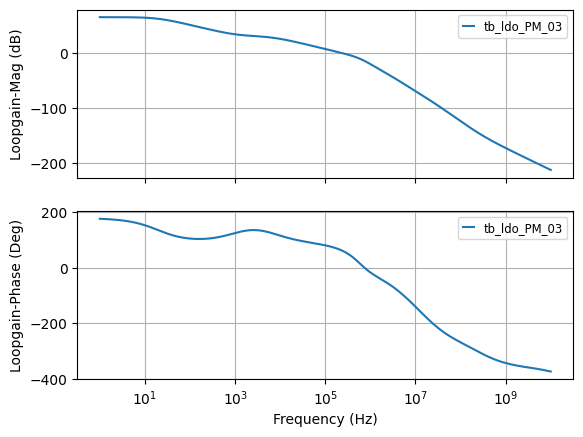

Unity-gain frequency (kHz): 245.4629
Phase at unity gain: 60.9856°


In [6]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np


def read_ngspice_raw(filename):
    
    path = Path(filename).expanduser().resolve()
    if not path.is_file():
        raise FileNotFoundError(f"No se hallo el archivo en la ruta: {path}")

    lines = path.read_text().splitlines()
    variables = int(next(line.split(':', 1)[1] for line in lines
                         if line.startswith('No. Variables:')))
    points = int(next(line.split(':', 1)[1] for line in lines
                      if line.startswith('No. Points:')))
    values_start = lines.index('Values:') + 1

    values = []
    for line in lines[values_start:]:
        fields = line.split()
        if not fields:
            continue
        # Point-header lines contain the point index and its first value.
        value_field = fields[1] if len(fields) >= 2 and re.fullmatch(r'\d+', fields[0]) else fields[0]
        values.append(float(value_field.split(',', 1)[0]))

    expected_values = points * variables
    if len(values) != expected_values:
        raise ValueError(
            f"Expected {expected_values} values in {path}, found {len(values)}"
        )

    return np.asarray(values).reshape(points, variables)


# The notebook is in /home/jaskun/python and the simulation output is in
# /home/jaskun/simulations/ngspice.
filename = Path('../simulations/ngspice/tb_ldo_PM_03.raw')
data = read_ngspice_raw(filename)
freq, loopgain_db, phase_deg = data.T

print(f"Variables: {data.shape[1]}")
print(f"Points: {data.shape[0]}")

fig, axs = plt.subplots(2, 1, sharex=True)
axs[0].semilogx(freq, loopgain_db, label='tb_ldo_PM_03')
axs[0].set_ylabel('Loopgain-Mag (dB)')
axs[0].grid()
axs[0].legend(loc='upper right', fontsize='small', handlelength=1.0)

axs[1].semilogx(freq, phase_deg, label='tb_ldo_PM_03')
axs[1].set_ylabel('Loopgain-Phase (Deg)')
axs[1].set_xlabel('Frequency (Hz)')
axs[1].grid()
axs[1].legend(loc='upper right', fontsize='small', handlelength=1.0)

plt.show()

pm0_freq = np.interp(0, np.flip(loopgain_db), np.flip(freq))/1000
pm0 = np.interp(pm0_freq*1000, freq, phase_deg)
print(f"Unity-gain frequency (kHz): {pm0_freq:.4f}")
print(f"Phase at unity gain: {pm0:.4f}°")
